<a href="https://colab.research.google.com/github/ReemaKhalaf1/INTELLIGENT-SYSTEM1-CI512/blob/main/Tutorial_5_Clustering_Analysis_Reema.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


In [45]:
df = pd.read_csv('customers.csv')

df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [46]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [47]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [48]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

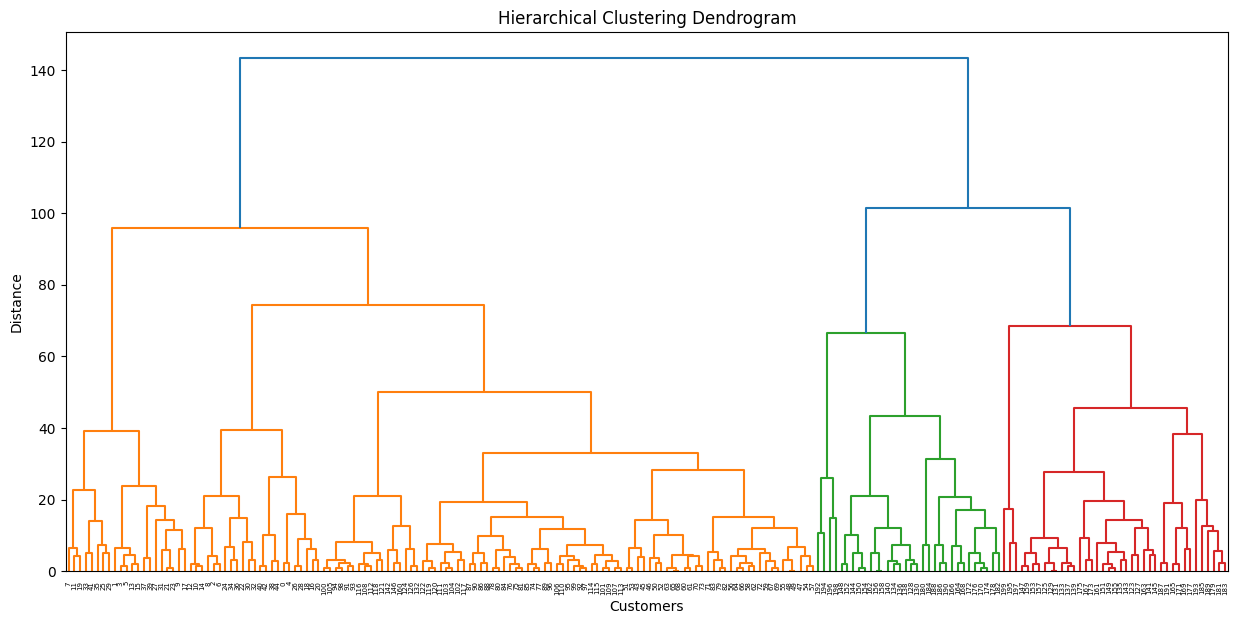

In [49]:
Z = linkage(X, method='complete')

plt.figure(figsize=(15, 7))

dendrogram(Z)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance')

plt.show()

In [50]:
hc = AgglomerativeClustering(
    n_clusters=2,
    linkage='complete'
)

labels = hc.fit_predict(X)


In [51]:
df['Cluster'] = labels

print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1    Male   19                  15                      39   
1             2    Male   21                  15                      81   
2             3  Female   20                  16                       6   
3             4  Female   23                  16                      77   
4             5  Female   31                  17                      40   
..          ...     ...  ...                 ...                     ...   
195         196  Female   35                 120                      79   
196         197  Female   45                 126                      28   
197         198    Male   32                 126                      74   
198         199    Male   32                 137                      18   
199         200    Male   30                 137                      83   

     Cluster  
0          1  
1          1  
2          1  
3          1  
4          1

In [52]:
print(df['Cluster'].value_counts())


Cluster
1    129
0     71
Name: count, dtype: int64


In [53]:
df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,87.830986,52.140845
1,45.550388,49.131783


In [54]:
dbscan_a = DBSCAN(eps=2, min_samples=2)

labels_a = dbscan_a.fit_predict(X)

print(labels_a)

[-1 -1  0  1 -1  1  0 -1 -1 -1  2 -1  2  3  2  3 -1 -1 -1 -1 -1  4 -1  4
 -1 -1  5 -1  5 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  6 -1  6 -1 -1 -1 -1 -1
  7  7 -1  8 -1  8  9 -1 -1  9 10  9 11 11 10 12 10 12 10 10 12 10 13 -1
 -1 13 14 15 15 14 15 14 15 15 14 14 15 14 -1 16 -1 -1 16 17 18 17 17 18
 18 18 17 18 17 18 -1 18 18 17 18 18 17 18 18 18 17 18 18 18 17 -1 17 19
 19 -1 -1 -1 -1 -1 20 -1 21 22 21 22 20 -1 23 -1 23 24 -1 24 23 -1 -1 -1
 -1 -1 -1 25 26 27 28 27 26 29 28 27 30 29 30 25 -1 -1 -1 -1 -1 31 -1 -1
 -1 -1 32 31 -1 -1 32 -1 32 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]


In [55]:
print("Number of clusters:", len(set(labels_a)) - (1 if -1 in labels_a else 0))

print("Number of outliers:", list(labels_a).count(-1))

Number of clusters: 33
Number of outliers: 94


In [56]:
DBSCAN(eps=2, min_samples=2)

DBSCAN(eps=2, min_samples=2)

In [57]:
dbscan_b = DBSCAN(eps=5, min_samples=5)

labels_b = dbscan_b.fit_predict(X)

print(labels_b)

[-1  0 -1  0 -1  0 -1 -1 -1  0 -1 -1 -1  0 -1  0 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1 -1 -1  2 -1  4  3  2  3  2 -1  2  3  4  3  2  3  2  3  4 -1  4
  3  4 -1  2 -1  4 -1  4 -1  2 -1  4  3  2  3  2 -1  4 -1  4 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]


In [58]:
print("Number of clusters:",
      len(set(labels_b)) - (1 if -1 in labels_b else 0))

print("Number of outliers:",
      list(labels_b).count(-1))

Number of clusters: 5
Number of outliers: 87


In [59]:
DBSCAN(eps=5, min_samples=5)


DBSCAN(eps=5)

In [60]:
dbscan_c = DBSCAN(eps=30, min_samples=20)

labels_c = dbscan_c.fit_predict(X)

print(labels_c)

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0 -1 -1]


In [61]:
print("Number of clusters:",
      len(set(labels_c)) - (1 if -1 in labels_c else 0))

print("Number of outliers:",
      list(labels_c).count(-1))

Number of clusters: 1
Number of outliers: 2


In [62]:
def calculate_silhouette(X, labels):

    mask = labels != -1

    X_filtered = X[mask]
    labels_filtered = labels[mask]

    n_clusters = len(set(labels_filtered))

    if n_clusters < 2 or n_clusters >= len(X_filtered):
        return "Cannot calculate Silhouette Score"

    return silhouette_score(X_filtered, labels_filtered)

In [63]:
score_a = calculate_silhouette(X, labels_a)
score_b = calculate_silhouette(X, labels_b)
score_c = calculate_silhouette(X, labels_c)

print("Experiment A:", score_a)
print("Experiment B:", score_b)
print("Experiment C:", score_c)

Experiment A: 0.583057377505917
Experiment B: 0.6181953232263256
Experiment C: Cannot calculate Silhouette Score


In [23]:
outliers_a = df[labels_a == -1]
outliers_b = df[labels_b == -1]
outliers_c = df[labels_c == -1]

print("Experiment A Outliers:")
print(outliers_a)

print("Experiment B Outliers:")
print(outliers_b)

print("Experiment C Outliers:")
print(outliers_c)

Experiment A Outliers:
     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1    Male   19                  15                      39   
1             2    Male   21                  15                      81   
4             5  Female   31                  17                      40   
7             8  Female   23                  18                      94   
8             9    Male   64                  19                       3   
..          ...     ...  ...                 ...                     ...   
195         196  Female   35                 120                      79   
196         197  Female   45                 126                      28   
197         198    Male   32                 126                      74   
198         199    Male   32                 137                      18   
199         200    Male   30                 137                      83   

     Cluster  
0          1  
1          1  
4          1  
7   

In [64]:
print("Experiment A Customer IDs:")
print(df.loc[labels_a == -1, 'CustomerID'].tolist())

print("\nExperiment B Customer IDs:")
print(df.loc[labels_b == -1, 'CustomerID'].tolist())

print("\nExperiment C Customer IDs:")
print(df.loc[labels_c == -1, 'CustomerID'].tolist())

Experiment A Customer IDs:
[1, 2, 5, 8, 9, 10, 12, 17, 18, 19, 20, 21, 23, 25, 26, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 44, 45, 46, 47, 48, 51, 53, 56, 57, 72, 73, 87, 89, 90, 103, 118, 122, 123, 124, 125, 126, 128, 134, 136, 139, 142, 143, 144, 145, 146, 147, 161, 162, 163, 164, 165, 167, 168, 169, 170, 173, 174, 176, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200]

Experiment B Customer IDs:
[1, 3, 5, 7, 8, 9, 11, 12, 13, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 45, 46, 124, 125, 127, 133, 143, 147, 149, 151, 153, 155, 161, 163, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200]

Experiment C Customer IDs:
[199, 200]
